# 01 EDA: IBM AML HI-Small

Queries `data/aml.duckdb` directly (build it with `src/load.py` then `src/patterns.py`). Figures go to `reports/figures/`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data/aml.duckdb"), read_only=True)
q = lambda sql: con.sql(sql).df()


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=120)

## 1. Volume over time

    first_ts             last_ts        n
0 2022-09-01 2022-09-18 16:18:00  5078345


,hour,n,rate
0,0,634726,0.000277
1,1,193728,0.000785
2,2,193143,0.000854


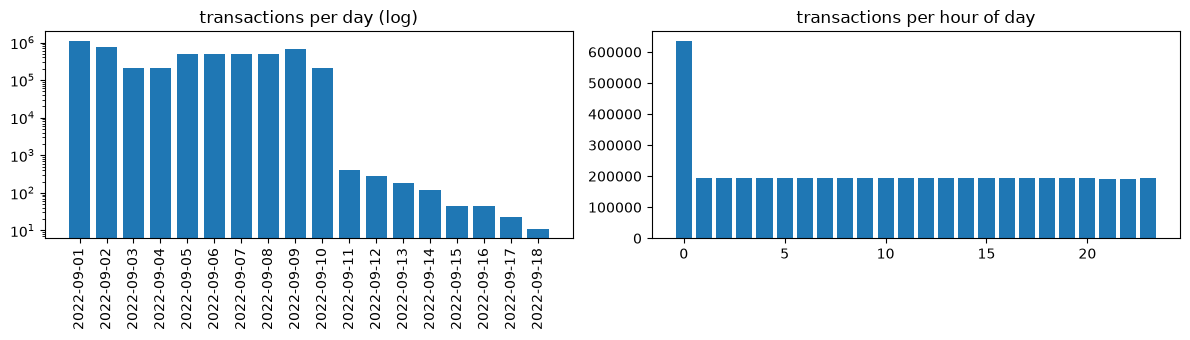

In [2]:
print(q("SELECT MIN(ts) first_ts, MAX(ts) last_ts, COUNT(*) n FROM transactions"))
daily = q("SELECT day, COUNT(*) n, SUM(is_laundering) pos, AVG(is_laundering) rate FROM transactions GROUP BY 1 ORDER BY 1")
hourly = q("SELECT hour, COUNT(*) n, AVG(is_laundering) rate FROM transactions GROUP BY 1 ORDER BY 1")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(daily.day.astype(str), daily.n); ax[0].set_yscale("log"); ax[0].set_title("transactions per day (log)"); ax[0].tick_params(axis="x", rotation=90)
ax[1].bar(hourly.hour, hourly.n); ax[1].set_title("transactions per hour of day")
save(fig, "01_volume")
hourly.head(3)

**Finding:** the data runs from 2022-09-01 00:00 to 2022-09-18 16:18, but 99.98% of rows fall on Sep 1–10. Volume swings by day: Sep 3–4 and Sep 10 have about 207k rows against about 480k on weekdays, and Sep 1 is the largest day (1.1M). By hour it is flat at about 193k, except hour 0 with 635k, a midnight batch. Timestamps are minute resolution, and 5.06M of 5.08M rows share their timestamp with another row, so the "strictly earlier" tie rule for features is essential.

## 2. Daily laundering rate

D:\DevTools\tmp\ipykernel_9740\1420553132.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  daily.assign(cum_share=daily.n.cumsum() / daily.n.sum(), rate_pct=daily.rate * 100).round(4)


,day,n,pos,rate,cum_share,rate_pct
0,2022-09-01,1114921,322.0,0.0003,0.2195,0.0289
1,2022-09-02,754449,408.0,0.0005,0.3681,0.0541
2,2022-09-03,207382,391.0,0.0019,0.4089,0.1885
3,2022-09-04,207430,407.0,0.0020,0.4498,0.1962
4,2022-09-05,482650,471.0,0.0010,0.5448,0.0976
5,2022-09-06,482089,531.0,0.0011,0.6398,0.1101
6,2022-09-07,482751,497.0,0.0010,0.7348,0.1030
7,2022-09-08,482773,539.0,0.0011,0.8299,0.1116
8,2022-09-09,654467,514.0,0.0008,0.9588,0.0785
9,2022-09-10,208325,442.0,0.0021,0.9998,0.2122


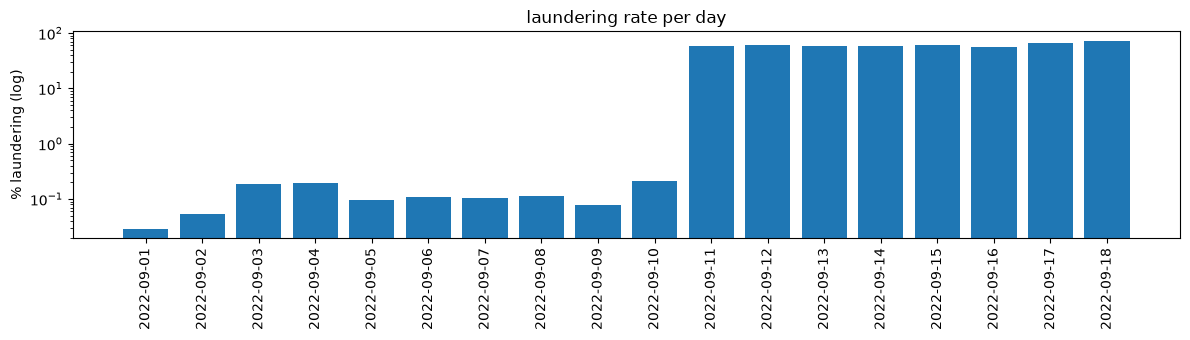

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(daily.day.astype(str), daily.rate * 100); ax.set_yscale("log"); ax.set_ylabel("% laundering (log)"); ax.tick_params(axis="x", rotation=90)
ax.set_title("laundering rate per day")
save(fig, "02_daily_rate")
daily.assign(cum_share=daily.n.cumsum() / daily.n.sum(), rate_pct=daily.rate * 100).round(4)

In [4]:
q("""SELECT day >= DATE '2022-09-11' AS tail, COUNT(*) n, SUM(is_laundering) pos,
       SUM((is_laundering = 1 AND tx_id NOT IN (SELECT tx_id FROM tx_pattern))::INT) unlisted
FROM transactions GROUP BY 1""")

,tail,n,pos,unlisted
0,True,1108,655.0,0.0
1,False,5077237,4522.0,1968.0


**Finding:** on Sep 1–10 the daily rate is 0.03–0.21%; it is highest on the low-volume days (Sep 3, 4, 10) because laundering per day stays near 400–540 while licit volume drops. Sep 11–18 is a **thin tail**: 1,108 transactions, 655 of them laundering (~59%), all from listed patterns and none unlisted. Attempts started in the main period are still running after licit generation stopped. That makes the tail an artifact of how the data was generated: any test set containing it gets an inflated base rate and easy positives. Cumulative volume reaches about 64% at the end of Sep 6 and about 83% at the end of Sep 8, so a 60/20/20 split by day is roughly train = Sep 1–6, val = Sep 7–8, test = Sep 9–10 (decided in T7).

## 3. Amounts

,payment_currency,is_laundering,n,median,p10,p90
0,Australian Dollar,0,136642,1298.980000,47.810000,5.090483e+04
1,Australian Dollar,1,127,5680.780000,491.250000,2.655003e+04
2,Bitcoin,0,146010,0.069816,0.001921,3.159291e+00
3,Bitcoin,1,56,0.247872,0.030426,9.907255e-01
4,Brazil Real,0,70646,5322.250000,176.625000,2.348372e+05
5,Brazil Real,1,57,25065.930000,1837.404000,1.045394e+05
6,Canadian Dollar,0,139914,1141.360000,39.023000,4.203351e+04
7,Canadian Dollar,1,128,7498.725000,967.097000,2.349719e+04
8,Euro,0,1166925,744.500000,25.890000,2.864138e+04
9,Euro,1,1372,5154.495000,442.692000,1.569974e+04


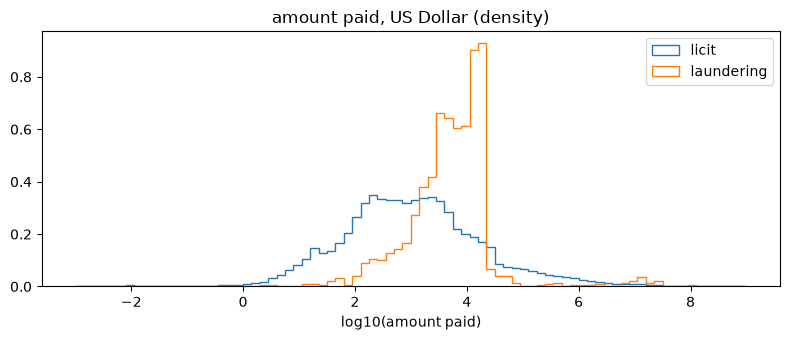

In [5]:
amt = q("SELECT log10(amount_paid) log_amt, is_laundering FROM transactions WHERE payment_currency = 'US Dollar' AND amount_paid > 0")
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, part in amt.groupby("is_laundering"):
    ax.hist(part.log_amt, bins=80, range=(-3, 9), density=True, histtype="step", label=["licit", "laundering"][label])
ax.set_xlabel("log10(amount paid)"); ax.legend(); ax.set_title("amount paid, US Dollar (density)")
save(fig, "03_amounts_usd")
q("""SELECT payment_currency, is_laundering, COUNT(*) n, quantile_cont(amount_paid, 0.5) median,
       quantile_cont(amount_paid, 0.1) p10, quantile_cont(amount_paid, 0.9) p90
FROM transactions GROUP BY ALL ORDER BY 1, 2""")

**Finding:** in USD, licit amounts are spread very widely (p10 ≈ \$31, median ≈ \$900, p90 ≈ \$35k), while laundering is concentrated in the middle (p10 ≈ \$640, median ≈ \$6k, p90 ≈ \$19k): fewer tiny payments and fewer very large ones. Laundering density drops off a cliff just under \$20k: 31% of USD laundering lies between \$10k and \$20k against 6% of licit, which looks like a structuring-style threshold in the generator. Amounts are in their own currency, so any amount feature needs a per-currency scale (log amount within currency, or conversion to USD) before it is comparable.

## 4. Currencies

   is_currency_mismatch        n     pos
0                 False  5006175  5177.0
1                  True    72170     0.0


,payment_currency,n,pos,rate_pct,mismatch_pct
0,Saudi Riyal,89014,374.0,0.420159,0.138181
1,Euro,1168297,1372.0,0.117436,1.248741
2,US Dollar,1895172,1912.0,0.100888,2.046252
3,Yen,155209,155.0,0.099865,1.034734
4,Australian Dollar,136769,127.0,0.092857,0.212768
5,Canadian Dollar,140042,128.0,0.091401,0.697648
6,Rupee,190202,167.0,0.087801,0.628805
7,Yuan,213752,184.0,0.086081,4.785920
8,Ruble,155178,133.0,0.085708,0.210081
9,Mexican Peso,110159,92.0,0.083516,0.456613


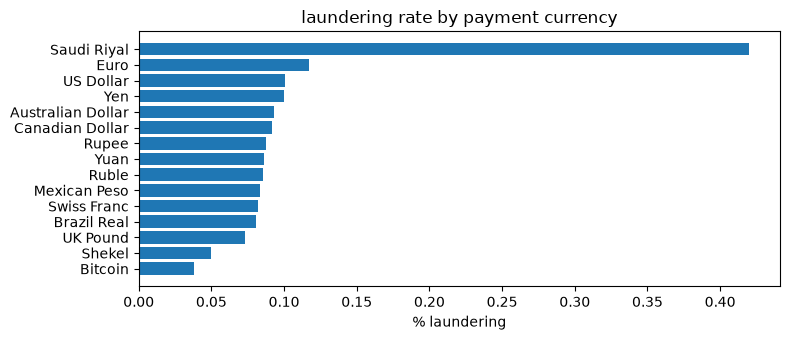

In [6]:
cur = q("""SELECT payment_currency, COUNT(*) n, SUM(is_laundering) pos, 100 * AVG(is_laundering) rate_pct,
       100 * AVG(is_currency_mismatch::INT) mismatch_pct
FROM transactions GROUP BY 1 ORDER BY rate_pct DESC""")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(cur.payment_currency, cur.rate_pct); ax.invert_yaxis(); ax.set_xlabel("% laundering"); ax.set_title("laundering rate by payment currency")
save(fig, "04_currency_rate")
print(q("SELECT is_currency_mismatch, COUNT(*) n, SUM(is_laundering) pos FROM transactions GROUP BY 1"))
cur

**Finding:** 15 currencies. Most have a laundering rate of 0.05–0.12%. The outliers are Saudi Riyal at 0.42% (374 positives on 89k rows) and, at the low end, Bitcoin (0.04%) and Shekel (0.05%). Currency mismatch (paid in one currency, received in another) covers 72k rows (1.4%) with **zero** laundering, and nearly all of them are ACH. So mismatch is a perfect *negative* shortcut in this synthetic data, not a positive one.

## 5. Payment formats

,payment_format,n,pos,rate_pct,share_of_laundering
0,ACH,600797,4483.0,0.746175,0.865946
1,Bitcoin,146091,56.0,0.038332,0.010817
2,Cash,490891,108.0,0.022001,0.020862
3,Cheque,1864331,324.0,0.017379,0.062585
4,Credit Card,1323324,206.0,0.015567,0.039791
5,Wire,171855,0.0,0.000000,0.000000
6,Reinvestment,481056,0.0,0.000000,0.000000


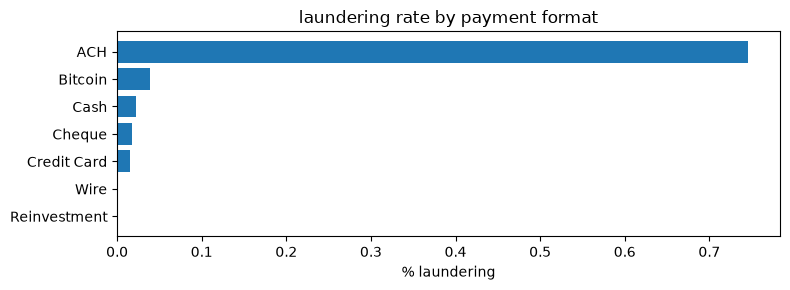

In [7]:
fmt = q("""SELECT payment_format, COUNT(*) n, SUM(is_laundering) pos, 100 * AVG(is_laundering) rate_pct,
       SUM(is_laundering) / (SELECT SUM(is_laundering) FROM transactions) share_of_laundering
FROM transactions GROUP BY 1 ORDER BY rate_pct DESC""")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(fmt.payment_format, fmt.rate_pct); ax.invert_yaxis(); ax.set_xlabel("% laundering"); ax.set_title("laundering rate by payment format")
save(fig, "05_format_rate")
fmt

**Finding:** ACH is 12% of transactions but **87% of laundering** (4,483 of 5,177; rate 0.75%, about 40× the other formats). Wire and Reinvestment have **zero** laundering. Cheque, Credit Card, Cash and Bitcoin sit at 0.02–0.04%. Payment format alone will be a strong baseline feature, so "is ACH" goes into T8 as a trivial scorer floor.

## 6. Accounts

accounts: 515,088, ever in laundering: 6,357 (1.23%)
       out_degree  in_degree
count    515088.0   515088.0
mean          9.9        9.9
std         285.1       13.0
min           0.0        0.0
50%           2.0        2.0
90%          28.0       29.0
99%          91.0       50.0
max      168672.0     1084.0


,is_self_transfer,n,pos
0,False,4487133,5166.0
1,True,591212,11.0


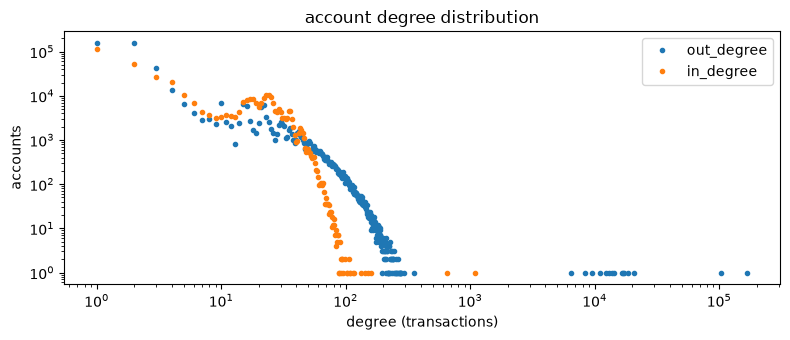

In [8]:
acct = q("""WITH ends AS (
    SELECT from_acct acct, 1 out_d, 0 in_d, is_laundering l FROM transactions
    UNION ALL SELECT to_acct, 0, 1, is_laundering FROM transactions)
SELECT acct, SUM(out_d) out_degree, SUM(in_d) in_degree, MAX(l) ever_laundering FROM ends GROUP BY 1""")
print(f"accounts: {len(acct):,}, ever in laundering: {acct.ever_laundering.sum():,} ({acct.ever_laundering.mean():.2%})")
print(acct[["out_degree", "in_degree"]].describe(percentiles=[0.5, 0.9, 0.99]).round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
for col in ["out_degree", "in_degree"]:
    counts = acct[col][acct[col] > 0].value_counts().sort_index()
    ax.loglog(counts.index, counts.values, ".", label=col)
ax.set_xlabel("degree (transactions)"); ax.set_ylabel("accounts"); ax.legend(); ax.set_title("account degree distribution")
save(fig, "06_degree")
q("SELECT is_self_transfer, COUNT(*) n, SUM(is_laundering) pos FROM transactions GROUP BY 1")

**Finding:** 515k accounts (bank + account), 1.23% of them touch at least one laundering transaction. Degrees are heavy-tailed: the median account sends 2 and receives 2, p99 is about 91 out and 50 in, and a few hub accounts send over 100k. The hubs are what make full-graph features expensive and why windowed features are needed. Self-transfers (12% of rows) carry only 11 laundering rows, close to a negative shortcut too.

## 7. Patterns

,pattern_type,n,in_tail
0,UNLISTED,1968,0.0
1,GATHER-SCATTER,716,254.0
2,SCATTER-GATHER,626,129.0
3,STACK,466,33.0
4,FAN-OUT,342,66.0
5,FAN-IN,318,66.0
6,CYCLE,287,44.0
7,BIPARTITE,263,22.0
8,RANDOM,191,41.0


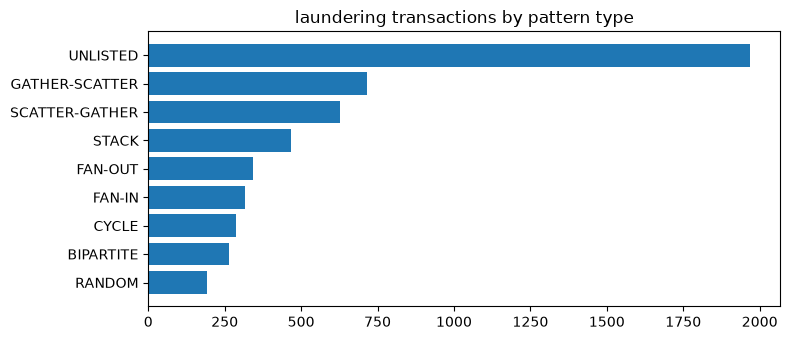

In [9]:
pat = q("""SELECT COALESCE(p.pattern_type, 'UNLISTED') pattern_type, COUNT(*) n,
       SUM((t.day >= DATE '2022-09-11')::INT) in_tail
FROM transactions t LEFT JOIN tx_pattern p USING (tx_id)
WHERE t.is_laundering = 1 GROUP BY 1 ORDER BY n DESC""")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(pat.pattern_type, pat.n); ax.invert_yaxis(); ax.set_title("laundering transactions by pattern type")
save(fig, "07_patterns")
pat

**Finding:** 38% of laundering (1,968) is UNLISTED, the largest group. Of the listed types, GATHER-SCATTER (716) and SCATTER-GATHER (626) are the biggest, and RANDOM (191) the smallest. GATHER-SCATTER and SCATTER-GATHER also dominate the thin tail. Recall by pattern needs per-type counts in the test split large enough to mean something; check this in T7.

## Shortcut-feature candidates

| Feature | Direction | Evidence |
|---|---|---|
| `payment_format = ACH` | strong positive | 87% of laundering, rate ≈ 40× other formats |
| `payment_format IN (Wire, Reinvestment)` | perfect negative | 0 laundering in 653k rows |
| `is_currency_mismatch` | perfect negative | 0 laundering in 72k rows |
| `is_self_transfer` | near-perfect negative | 11 laundering in 591k rows |
| `is_cross_bank` | positive | 98% of laundering vs 86% of all rows |
| `payment_currency = Saudi Riyal` | positive | rate 0.42% vs ≈0.1% |

These are real signal in the synthetic generator, not leaks, but they make the per-transaction baseline strong. The graph-feature ablation has to beat a baseline that already uses them.